# Workshop General Info

## Submitting the Assignment

This is the 4th workshop assignment, worth 1.2 CATs in total.

Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart Kernel) and then **run all cells** (in the menubar, select Run$\rightarrow$Run All Cells). There are no marks for "what my code used to do before I changed it".

Make sure you fill in any place that says `YOUR CODE HERE`. Answer any text-based questions and double-check that you have given any variables you create the names you are asked to give them.

A submission that passes all the tests will pass overall, but there are often marks for hidden tests you cannot see.

For submission via the nbgrader interface: once finished, go back to the "Assignments" tab and click submit. You can do this again if you are not happy with your answers. This submits a version of the notebook with all outputs cleared.

Please enter your name as a string, in the box below in case files go astray. E.g.:

```
NAME = "Albert Bartok-Partay"
```
Feedback will be released through the nbgrader interface: you can go back to the Assignments tab again to download it.

In [1]:
NAME = "Jabir Hussain"
# when running on biochem legacy, it needed this pip install
# on the regular biochem server, it is not needed
#!pip install pybind11>=2.12

In [2]:
# Only run this cell once.
!pip install --user tqdm

In [3]:
import random
import math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from tqdm import tqdm

In [4]:
%matplotlib widget

### Fitting a pair potential

We have calculated the pair interaction of two Ar atoms using Coupled Cluster theory (a very high level quantum mechanical method) at a number of interatomic distances. The data is presented below. The goal of this part is to fit a pair potential using the quantum mechanical data.

In [5]:
# Interaction energies of the Ar dimer

dimer_r = np.array([3.2, 3.4, 3.6, 3.8, 4.0 , 4.2, 4.4, 4.6, 4.8, 5.0 , 5.2, 5.4, 5.6,
       5.8, 6.0 ]) # In Angstroms
dimer_energy = np.array([ 0.01825327, -0.00592132, -0.01401127, -0.01516231, -0.01362215,
       -0.01130646, -0.00903431, -0.00709958, -0.00556213, -0.00437844,
       -0.0034723 , -0.00277569, -0.00223146, -0.00180152, -0.00145594]) # In eV

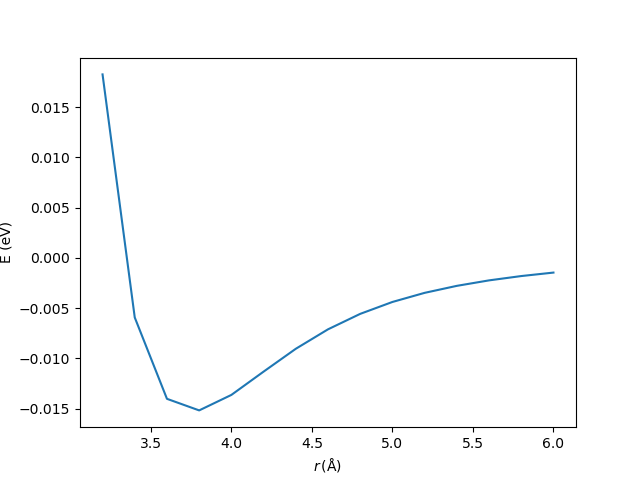

In [6]:
# Plot the data

fig, ax = plt.subplots()
ax.plot(dimer_r,dimer_energy)
ax.set_xlabel(r"$r\,(\rm{\AA})$")
ax.set_ylabel(r"E (eV)")
plt.show()

### Fitting
Use the Lennard Jones functional form
$$
U(r) = 4 \epsilon \left[ \left( \frac{\sigma}{r}\right)^{12}-\left( \frac{\sigma}{r}\right)^{6} \right]
$$
to model the data. Determine $\epsilon$ and $\sigma$ such that the model is a good fit.

#### Possible strategies:
* Non-linear fitting to minimise the mean-square deviation
* Fit the location and depth of the minimum

I recommend using the second approach. Hints to obtain $\sigma$:
* It is possible to express the location of the minimum of the LJ formula analytically. Differentiate the $U(r)$ function: it will be zero at the minimum. Solve the equation $U'(r) = 0$ for $r$.
* Alternatively, solve the equation $U(r) = 0$.
By either of the above, you should be able to get a reasonable estimate for $\sigma$ by inspecting the data points.
Hint for $\epsilon$:
* Determine the value of $U(r_\mathrm{min})$.
Again, inspect the numerical values of the data points to find $\epsilon$.
---
#### Task:
* Determine approximate values of $\sigma$ and $\epsilon$.
* Plot the original data and your fit.

[2 marks]

We will express the location of the minimum of the LJ formula analytically by solving $U'(r) = 0.$

$$U(r)=4\epsilon\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6\right].$$

Differentiating gives $$\frac{dU}{dr}
=4\epsilon\left[-12\frac{\sigma^{12}}{r^{13}}+6\frac{\sigma^6}{r^7}\right].$$

We then set $\frac{dU}{dr} = 0$:

$$-12\frac{\sigma^{12}}{r^{13}}+6\frac{\sigma^6}{r^7}=0$$

Rearranging gives us $$\frac{\sigma^6}{r^6}=\frac12,$$

And thus we find $$r_{\min}=2^{1/6}\sigma
\qquad\Rightarrow\qquad
\sigma=\frac{r_{\min}}{2^{1/6}}.$$

From the provided NumPy arrays, we find that $$r_{\min} = 3.8, \quad U(r_{\min}) = -0.01516231,$$
$$ \epsilon = -U(r_{\min}) = 0.01516231 \text{eV}, $$
$$ \sigma = \frac{r_{\min}}{2^{\frac{1}{6}}} = \frac{3.8}{2^{\frac{1}{6}}} = 3.385415... = 3.3854 \mathring{A}$$

epsilon ≈ 0.015162 eV
sigma   ≈ 3.385415 Å


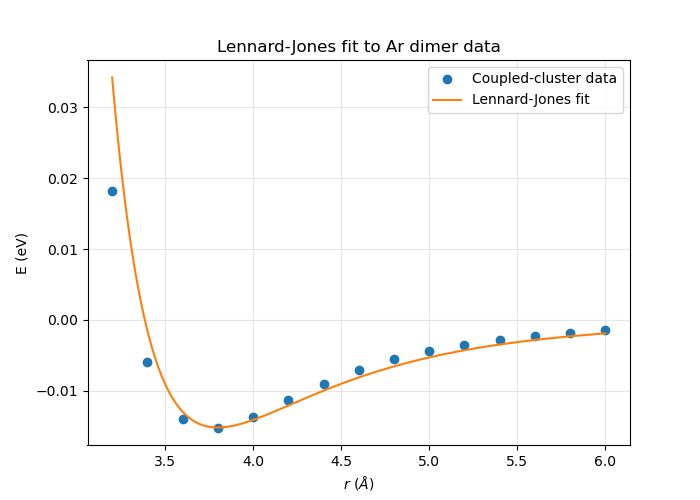

In [7]:
r_min = 3.8
U_min = -0.01516231

epsilon = -U_min
sigma = r_min / (2**(1/6))

def LJ(r, epsilon, sigma):
    return 4 * epsilon * ( (sigma / r)**12 - (sigma/r)**6 )

r_fit = np.linspace(3.2, 6.0, 400)
U_fit = LJ(r=r_fit, epsilon=epsilon, sigma=sigma)

print(f"epsilon ≈ {epsilon:.6f} eV")
print(f"sigma   ≈ {sigma:.6f} Å")

plt.figure(figsize=(7,5))
plt.plot(dimer_r, dimer_energy, 'o', label='Coupled-cluster data')
plt.plot(r_fit, U_fit, '-', label='Lennard-Jones fit')
plt.xlabel(r"$r$ ($\AA$)")
plt.ylabel("E (eV)")
plt.title("Lennard-Jones fit to Ar dimer data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

YOUR ANSWER HERE

### Simulating the hard disc model
The hard disc model is defined by the pair interaction

$$
U(r) =
\begin{cases}
\infty \quad \rm{if} \quad r\le r_0\\
0\quad \rm{if} \quad r> r_0
\end{cases}
$$

meaning that overlapping particles are forbidden, but particles do not interact otherwise. This model would lead to infinite forces, which is impossible to simulate numerically. However, in practice, we can model this in a molecular dynamics simulation which considers elastic collisions between the particles. At any given phase space point, we calculate when each pair would collide next. We choose the minimum value $\Delta t$ of these (the earliest collision) and propagate the system by updating the positions of the particles as
$$
\mathbf{r}_i(t+\Delta t) = \mathbf{r}_i(t) + \mathbf{v}_i \Delta t
$$
We then update the velocities of the two colliding particles according to the elastic collision rules, and recalculate the next collision times, after which the procedure is repeated.

Luckily, we only need to explicitly calculate the collision times of the particles that have just collided, as all the other collision times can be updated by subtracting $\Delta t$ from each.

The code below implements this algorithm.

In [8]:
def collision_time(r,v,i,j,radius=None):
    """Determines the collision time between particles i and j. Positions and velocities are stored in 
    numpy arrays r and v. Optionally, radii of the particles are given in the numpy array radius -
    taken as one if not given"""
    
    delta_r = r[i]-r[j]
    delta_v = v[i]-v[j]
    
    if radius is None:
        ri = 1
        rj = 1
    else:
        ri = radius[i]
        rj = radius[j]
    
    a = np.sum(delta_v**2)
    b = 2*np.dot(delta_r,delta_v)
    c = np.sum(delta_r**2) - (ri+rj)**2
    discriminant = b**2 - 4*a*c
    if discriminant > 0:
        # they are on collision course
        time = (-b - np.sqrt(discriminant)) / (2*a)
    else:
        # they will miss
        time = float('inf')

    if time < 0:
        # they have collided in the past
        time = float('inf')
    return time

def collision(r,v,i,j,fix_i=False,fix_j=False):
    """Update the velocity of two colliding particles assuming a fully elastic collision.
    If j is fixed, its mass is considered infinity."""
    
    unit_paral_ij = r[i] - r[j]
    unit_paral_ij /= np.linalg.norm(unit_paral_ij)
    unit_ortho_ij = np.zeros(2)
    unit_ortho_ij[0] = unit_paral_ij[1]
    unit_ortho_ij[1] = -unit_paral_ij[0]
    
    vi_paral = np.dot(unit_paral_ij,v[i])
    vj_paral = np.dot(unit_paral_ij,v[j])
    vi_ortho = np.dot(unit_ortho_ij,v[i])
    vj_ortho = np.dot(unit_ortho_ij,v[j])
   
    if fix_j:
        v[i] = vi_ortho*unit_ortho_ij-vi_paral*unit_paral_ij
    if fix_i:
        v[j] = vj_ortho*unit_ortho_ij-vj_paral*unit_paral_ij
    else:
        v[i] = vi_ortho*unit_ortho_ij + vj_paral*unit_paral_ij
        v[j] = vj_ortho*unit_ortho_ij + vi_paral*unit_paral_ij

def get_collision_times(r,v,radius=None):
    """ Calculate the matrix of collision times """
    n = len(r)
    times = np.zeros((n,n))
    for i in range(n):
        for j in range(n):
            if i == j:
                times[i,j] = float('inf')
            elif i < j:
                times[i,j] = times[j,i] = collision_time(r,v,i,j,radius=radius)
            
    return times
    
def update_collision_times(r,v,times,i,j,radius=None):
    n = len(r)
    for k in range(n):
        if i != k:
            times[i,k]= times[k,i] = collision_time(r,v,i,k ,radius=radius)
        if j != k:
            times[j,k]= times[k,j] = collision_time(r,v,j,k ,radius=radius)
            
def propagate(r,v,time):
    r += v*time

### The simulation
You will enclose the particles in the box, and use reflective boundary conditions: the balls will bounce off the walls. In this application, the walls will be hard discs which have their positions fixed.

The initial positions of the moving particles will be generated on a grid, but you will give them random initial velocities. The first part of the simulation, until the initial configuration is "forgotten" will have to be discarded - this is called **equilibration** or sometimes **burn-in**.

The cell below sets up the walls and the particles. The initial positions of the particles could be anything, with the only constraint that they may not overlap.

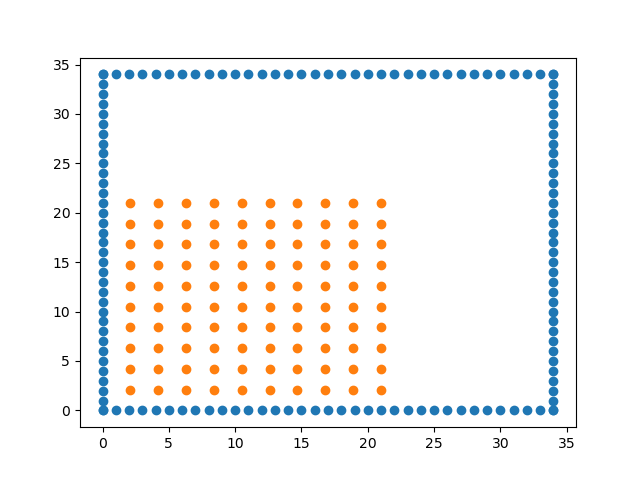

In [9]:
# size of the simulation box
n_x = 35 #100
n_y = 35 #100

# build the walls as fixed discs
walls = np.concatenate(
(np.array([np.arange(n_x),np.zeros(n_x)]).T,
np.array([np.arange(n_x),(n_y-1)*np.ones(n_x)]).T,
np.array([np.zeros(n_y),np.arange(n_y)]).T,
np.array([(n_x-1)*np.ones(n_y),np.arange(n_y)]).T,
))

# an n_particles_x by n_particles_y grid of particles initially arranged in a rectangle
n_particles_x = 10
n_particles_y = 10

x,y = np.meshgrid(2.1+2.1*np.arange(n_particles_x),2.1+2.1*np.arange(n_particles_y))
particles = np.array([x.flatten(),y.flatten()]).T

n_wall = len(walls)
n_particle = len(particles)

r = np.concatenate((walls,particles))
v = np.zeros_like(r)

# random velocities
v[n_wall:,:] = np.random.rand(n_particle,2)-0.5

# do not let wall particles to move
fix = np.zeros((n_wall+n_particle),dtype="bool")
fix[:n_wall] = True

fig,ax = plt.subplots()
ax.scatter(walls[:,0],walls[:,1])
ax.scatter(particles[:,0],particles[:,1])
plt.show()

The next cell puts everything together and runs a simulation with the hard discs. You can follow the progress in the indicator - it should take about a minute to run this simulation.

In [10]:
n_steps = 5000
times = get_collision_times(r,v)

r_traj = []
t_traj = []
d_traj = []

for i_step in tqdm(range(n_steps)):
    i,j = np.unravel_index(np.argmin(times, axis=None), times.shape)
    time = times[i,j]
    
    propagate(r,v,time)
    times -= time
    collision(r,v,i,j,fix[i],fix[j])
    update_collision_times(r,v,times,i,j)
    
    r_traj.append(r*1)
    t_traj.append(time*1)

    

100%|██████████| 5000/5000 [00:27<00:00, 178.98it/s]


Finally, you can watch the simulation as a movie. You need to remember that the timesteps are changing rather than being constant - this is why it does not appear smooth. We could have interpolated the trajectory to make it look continuous.

In [11]:
%matplotlib notebook

<IPython.core.display.Javascript object>

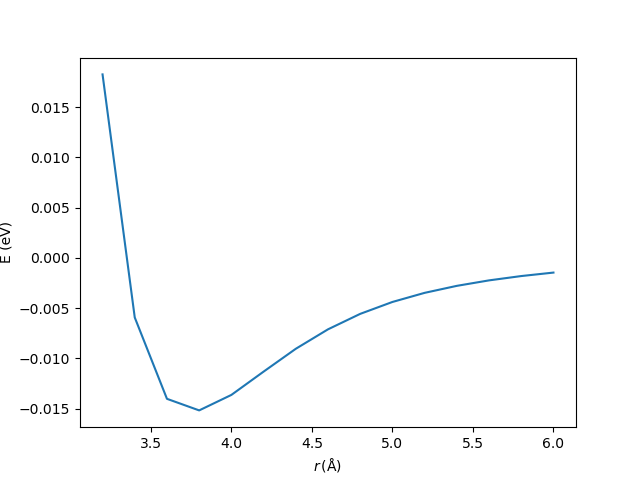

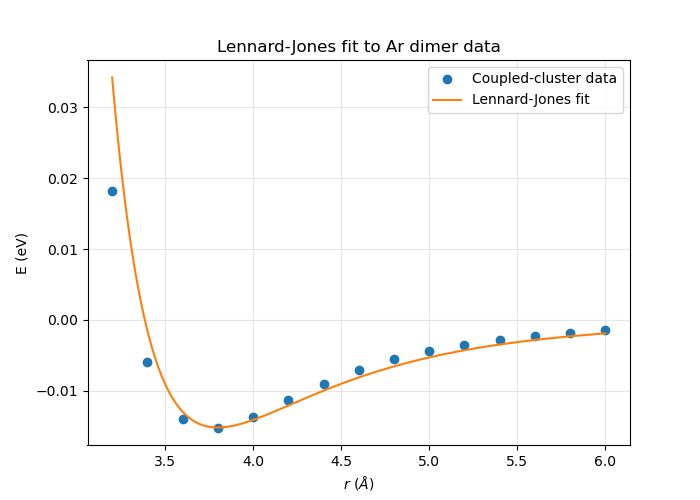

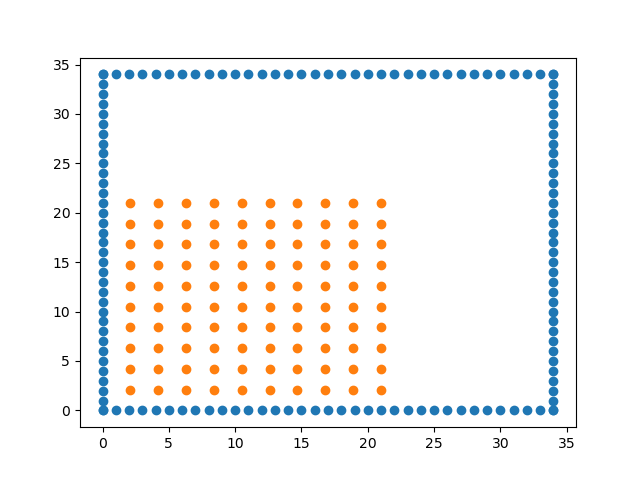

In [12]:
fig, ax = plt.subplots()

wall0, = ax.plot(r_traj[0][:n_wall,0],r_traj[0][:n_wall,1],"rs",markersize=20)
ax.set_aspect("equal")
disc_size = 7

point0, = ax.plot(r_traj[0][n_wall:,0],r_traj[0][n_wall:,1],"bo",markersize=disc_size)
text = ax.text(0,0,f"step = {0}")

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")

def animate(i):
    point0.set_xdata(r_traj[i][n_wall:,0])
    point0.set_ydata(r_traj[i][n_wall:,1])
    text.set_text(f"step = {i}")
    
    return point0

ani = animation.FuncAnimation(
    fig, animate, frames=n_steps,interval=10, blit=True)

# In case you want to save it as a movie 
#ani.save("HD.mp4")

plt.show()

#### Task:

You collected the times between collisions in the variable `t_traj`. Plot this variable as a function of steps below and observe how the times vary as the simulation progresses. A logarithmic scale may work better. Comment on the graph.

[1 mark]

In [13]:
plt.figure(figsize=(7,4))
plt.plot(t_traj)
plt.yscale('log')
plt.xlabel('Collision step')
plt.ylabel(r'$\Delta t$ to next collision')
plt.title('Time between collisions during the simulation')
plt.grid(True, alpha=0.3)
plt.show()

<IPython.core.display.Javascript object>

The time between collisions varies significantly in the simulation across multiple orders of magnitude, from $10^{-5}$ to $0.5$ seconds. In the early part of the simulation, the $\Delta t$ values increase as the system adjusts from the initial configuration during the burn-in phase. As the simulation progresses, the plot shows more stability: $\Delta t$ fluctuates strongly across the same range of values, suggesting the system has near-equilibrated and the initial configuration has been forgotten. The sharp downward spikes reflect rapid collisions in succession, whereas upward spikes show intervals where more time is taken before the next collision.

#### Task
Repeat the simulation at different densities: change the size of the bounding box from 100 x 100 to other sizes. At each density, calculate the average time between collisions (after discarding the burn-in period). Plot the average times between collisions as the function of the density. What can you observe? Do you have a qualitative explanation? It may be worthwile using a logarithmic scale on the $y$ axis.

Suggested box sizes for 100 particles: $200^2$, $70^2$, $52^2$, $43^2$, $37^2$, $33^2$, $30^2$, $28^2$, $26^2$, $25^2$. Feel free to share the workload with others and pool your data.

[4 marks]

---
#### Extension task
Extend the code such that it keeps track of the distance travelled by each particle between collisions. Calculate the mean of these to obtain the **mean free path**, and plot this quantity as a function of the density.

YOUR ANSWER HERE

### The Optimal Velocity (OV) model

The OV model can be used to describe traffic flows. Here, the car-driver unit (labelled as $i$) is represented as a particle and the model mimicks the decision of the driver based on 
* the desired speed ($v_0$)
* the distance between the car in front ($s_i$).

For a given distance $s$ there is an optimal velocity $v_{\textrm{opt}}(s)$. The driver inputs an acceleration according to
$$ a_i = \frac{\mathrm{d}v}{\mathrm{d}t} =  \frac{v_{\textrm{opt}}(s_i) - v_i}{\tau} $$

where $\tau$ is the characteristic time a driver reacts.

In this workshop, we will use the optimal velocity model based on
$$ v_{\textrm{opt}}(s) = v_0 \frac{\tanh(\frac{s}{\Delta s}-\beta) + \tanh \beta}{1+\tanh \beta}$$

where $\beta$ is a form factor and $\Delta s$ adjusts the length scale of the optimal velocity, that is, how comfortable a driver is with a given following distance.

#### Task

In the cell below, implement this function.

[0.25 marks]


In [17]:
# Motorway settings (based on https://mtreiber.de/Vkmod_Skript/Lecture08_Micro1.pdf)
tau = 0.65 # s
v_0 = 30 # m/s 
delta_s = 15 # m
beta = 1.5 # 1.5

# City settings (based on https://mtreiber.de/Vkmod_Skript/Lecture08_Micro1.pdf)
# tau = 0.65 # s
# v_0 = 15 # m/s 
# delta_s = 8 # m
# beta = 1.5 # 1.5

def v_opt(s, v_0=v_0, delta_s=delta_s, beta=beta):
    return v_0 * (np.tanh(s / delta_s - beta) + np.tanh(beta)) / (1 + np.tanh(beta))

Test your implementation below - make sure here you are using
$$v_0 = 30~\textrm{m s}^{-1}$$ 
$$ \Delta s = 15~\textrm{m}$$
$$ \beta = 1.5 $$

In [18]:
assert np.isclose(v_opt(0),0.0)
assert np.isclose(v_opt(4),0.9700784)
assert np.isclose(v_opt(8),2.4866164)
assert np.isclose(v_opt(16),7.8268712)
assert np.isclose(v_opt(32),23.0768097)
assert np.isclose(v_opt(64),29.8760025)

#### Task

Plot $v_\textrm{opt}$ at a range of $s$ values. Try out different $v_0$, $\Delta s$ and $\beta$ value and interpret how they affect the model. In the cell below, discuss your findings: how does the model work?

[0.5 marks]

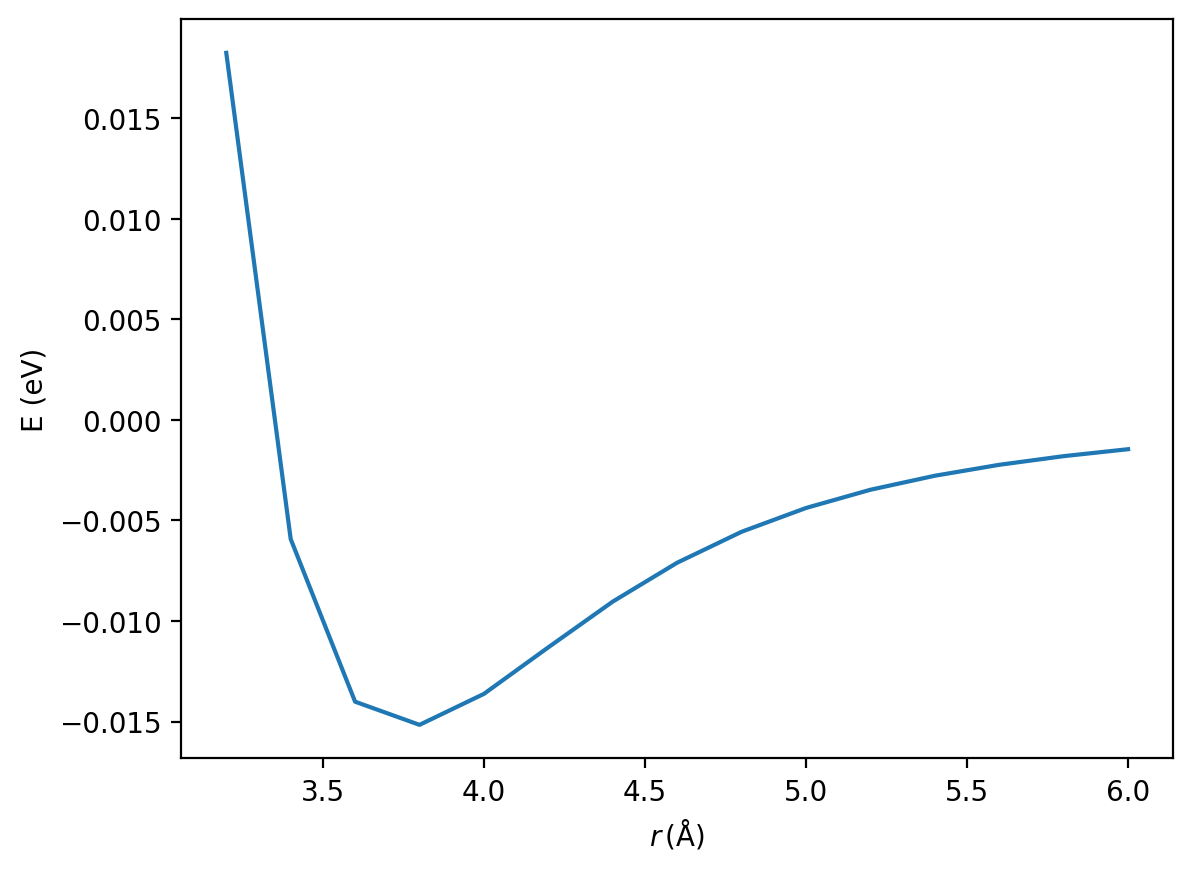

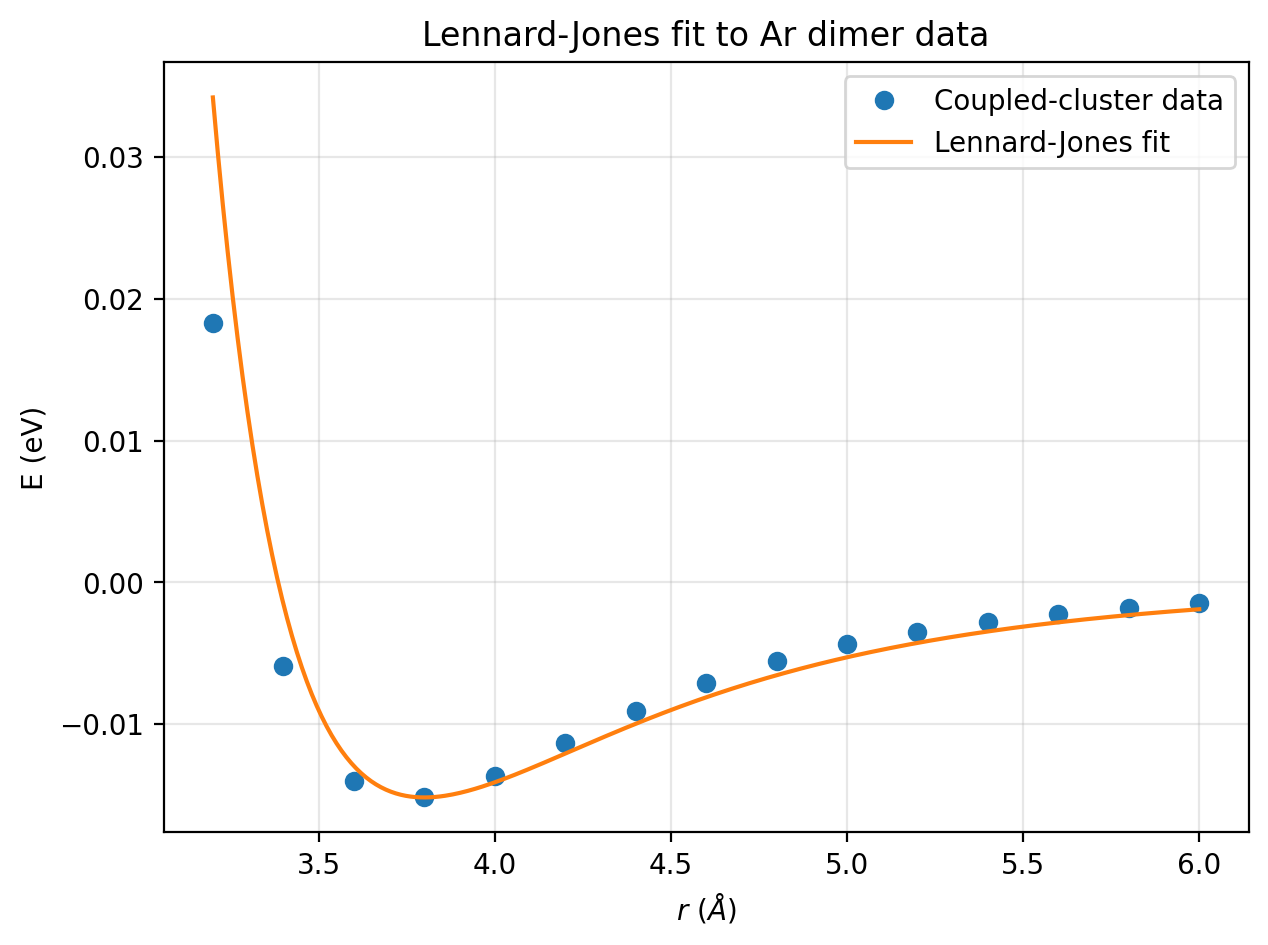

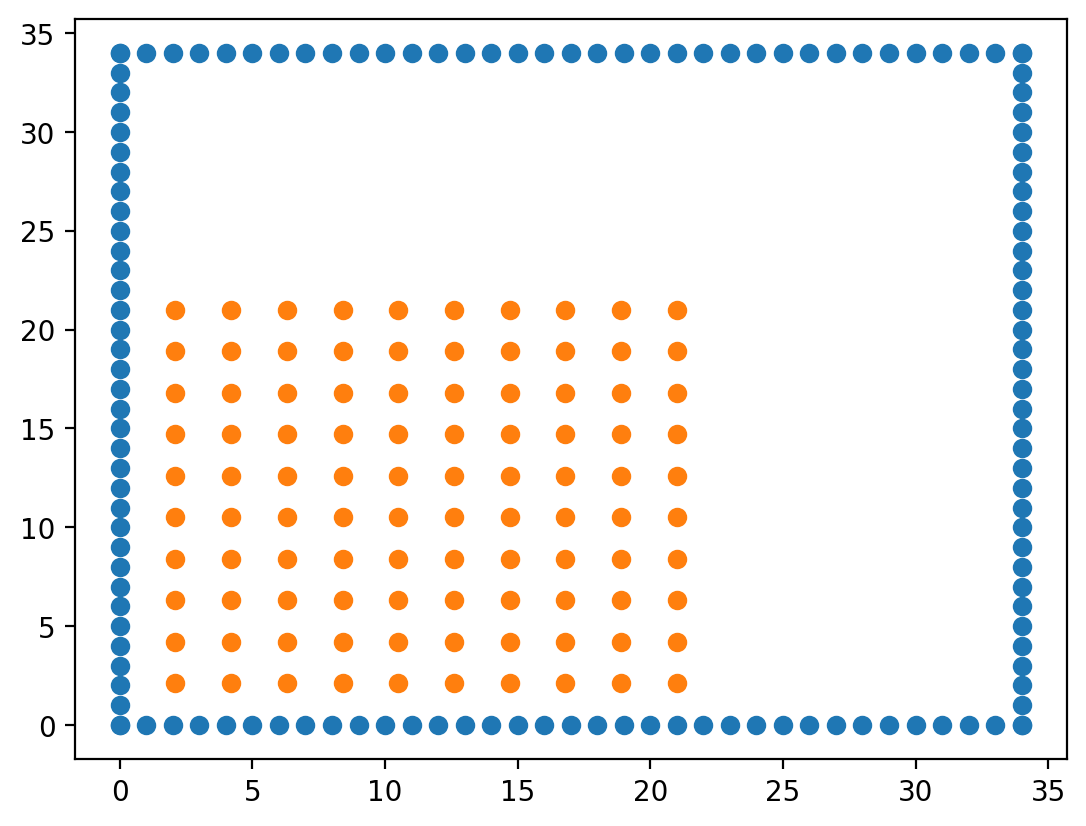

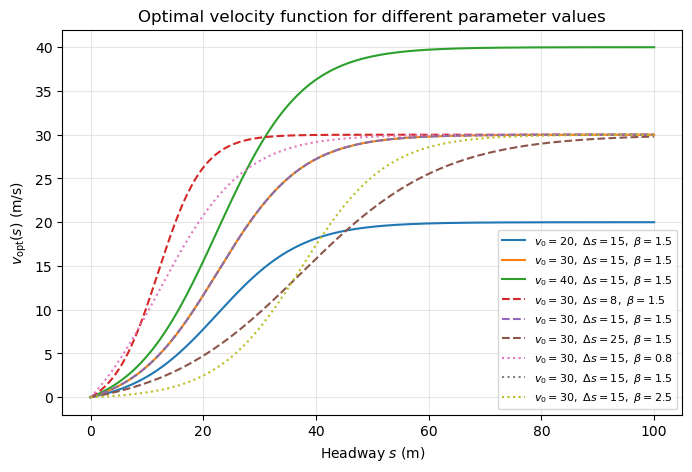

In [20]:
s = np.linspace(0, 100, 500)

v0_values = [20, v_0, 40]
delta_s_values = [8, delta_s, 25]
beta_values = [0.8, beta, 2.5]

%matplotlib inline
plt.figure(figsize=(8, 5))

for v0_trial in v0_values:
    plt.plot(
        s,
        v_opt(s, v0_trial, delta_s, beta),
        label=fr"$v_0={v0_trial},\ \Delta s={delta_s},\ \beta={beta}$"
    )
for delta_s_trial in delta_s_values:
    plt.plot(
        s,
        v_opt(s, v_0, delta_s_trial, beta),
        linestyle="--",
        label=fr"$v_0={v_0},\ \Delta s={delta_s_trial},\ \beta={beta}$"
    )
for beta_trial in beta_values:
    plt.plot(
        s,
        v_opt(s, v_0, delta_s, beta_trial),
        linestyle=":",
        label=fr"$v_0={v_0},\ \Delta s={delta_s},\ \beta={beta_trial}$"
    )

plt.xlabel("Headway $s$ (m)")
plt.ylabel(r"$v_{\mathrm{opt}}(s)$ (m/s)")
plt.title("Optimal velocity function for different parameter values")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8)
plt.show()

The plot shows that increasing $v_0$ raises the curves plateau, setting the maximum speed. The $\Delta s$ variable directly affecting the response, with low $\Delta s$ having a sharper response as opposed to high $\Delta s$ having a more gradual rise. This tells us how much space the driver needs before accelerating. $\beta$ affects where the steepness of the curve is, showing the drivers sensitivity at short distances. As $\beta$ grows, so does the delay in the speed increase. 

The model converts the headway $s_i$ into the target speed $v_{\text{opt}}(s_i)$, updating the car's motion by the acceleration law $$a_i = \frac{v_{\text{opt}}(s_i) - v_i}{\tau}.$$ If $v_i < v_{\text{opt}}(s_i)$ then the car accelerates, decelerating in the other case.

In your simulation, the cars will move on a ring - in other words, they will be subject to periodic boundary conditions. This will allow us to model the steady state without worrying about what happens at the edges of the peloton. We will assume that the ring has a circumference of $L$. To model periodic boundary conditions, I recommend the following numerical approach:

$$ s_i = {x_{i+1} - x_i} - \left\lfloor \frac{x_{i+1} - x_i}{L} \right\rfloor L$$

where $\lfloor y \rfloor$ indicates the *floor* function, i.e. returns the greatest integer that is less than or equal to $y$. It is accessed as `np.floor`.

#### Task

Implement the distance function below and test it.

[0.25 marks]

In [32]:
def distance(x, L):
    x = np.asarray(x)
    dx = np.roll(x, -1) - x
    return dx - np.floor(dx / L) * L

In [33]:
assert np.all(distance([0,100],1000) == np.array([100,900]))
assert np.all(distance([500,600],1000) == np.array([100., 900.]))
assert np.all(distance([1200,1300],1100) == np.array([100., 1000.]))

In [34]:
# The acceleration function

def acceleration(s,v):
    return (v_opt(s)-v)/tau

The cell below runs a simulations on a 1 km circumference circle with 20 cars, starting from an initial condition where the cars are equispaced and stationary. 

In [44]:
# Model parameters
tau = 0.65 # s
v_0 = 30 # m/s 
delta_s = 15 # m
beta = 1.5 # 1.5

# Simulation parameters
L = 1000 # m
n_cars = 40
noise = 0.0 # m

# Initial conditions
x = np.linspace(0,L,n_cars,endpoint=False)
x += np.random.randn(n_cars)*noise
v = np.zeros_like(x)

# Integration timestep
dt = 0.1 # s
# number of integration steps
n = 36000 

s = distance(x,L)
a = acceleration(s,v)

travel = []
velocities  = []

# We use the velocity verlet algorithm
for i in range(n):
    v += 0.5*a*dt
    x += v*dt
    s = distance(x,L)
    a = acceleration(s,v)
    v += 0.5*a*dt

    travel.append(x*1)
    velocities.append(v*1)

travel = np.array(travel)
velocities = np.array(velocities)

Plot the velocity of one of the cars as a function of time. Vary the density of the cars in the previous cell, trying up to 100 cars per km.  

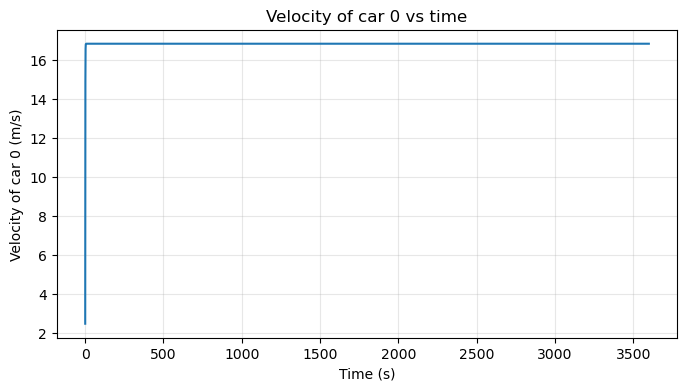

In [45]:
i_car = 0

t = np.arange(n) * dt

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, velocities[:, i_car])

ax.set_xlabel("Time (s)")
ax.set_ylabel(f"Velocity of car {i_car} (m/s)")
ax.set_title(f"Velocity of car {i_car} vs time")
ax.grid(True, alpha=0.3)

plt.show()

#### Task

Run simulations systematically for numbers of cars in `np.arange(2,100,4)`.

[1 mark]

Inspect the velocity vs time graph and find an appropriate burn-in time. Calculate the flow of cars (average velocity multiplied by the density) at each density after discarding the transient velocities before the burn-in. Plot the average velocity as a function of density. Comment on the result.

[1 mark]

In [47]:
L = 1000 # m

def run_all(n_cars):
    positions = np.linspace(0, L, n_cars, endpoint=False)
    positions += np.random.rand(n_cars) * noise
    velocities = np.zeros_like(positions)

    headways = distance(positions, L)
    accelerations = acceleration(headways, velocities)

    travel = []
    velocities_history = []

    for _ in range(n):
        velocities += 0.5 * accelerations * dt
        positions += velocities * dt
        headways = distance(positions, L)
        accelerations = acceleration(headways, velocities)
        velocities += 0.5 * accelerations * dt

        travel.append(positions.copy())
        velocities_history.append(velocities.copy())

    return np.array(travel), np.array(velocities_history)

travel_all = []
velocities_all = []

noise = 0.0 # m
density = np.arange(2,100,4)

for n_cars in tqdm(density):
    t_all, v_all = run_all(n_cars)
    travel_all.append(t_all)
    velocities_all.append(v_all)

100%|██████████| 25/25 [00:33<00:00,  1.33s/it]


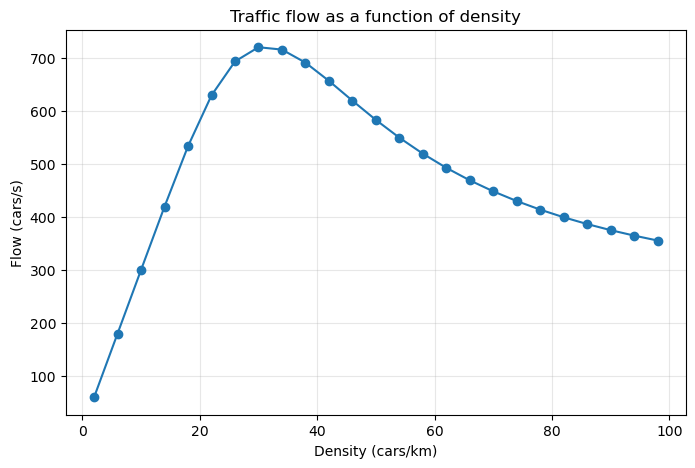

In [48]:
n_burnin = 5000

average_velocity = np.array([
    np.mean(v_i[n_burnin:, :])
    for v_i in velocities_all
])

flow = average_velocity * density

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(density, flow, 'o-')
ax.set_xlabel("Density (cars/km)")
ax.set_ylabel("Flow (cars/s)")
ax.set_title("Traffic flow as a function of density")
ax.grid(True, alpha=0.3)
plt.show()

Traffic flow begins to increase with denisty, reaching a peak around 30 cars/km. Following on from this peak, the density reduces. At low density, vehicles are weakly coupled and can travel near the free-flow speed, increasing the flow as the car count increases. At higher density, the headway between the vehicles become small such that the interactions limit the average speed. This means that despite the density increasing, the total flow decreases, a direct symptom of congestion in traffic flow.

#### Task

Repeat the previous task but use `noise = 0.1` for `n_cars in np.arange(2,100,4)`. Use the animation to assess the behaviour of cars at different densities. Look at the velocities of individual cars at various densities. What do you find and why?

[1 mark]

100%|██████████| 25/25 [00:33<00:00,  1.33s/it]


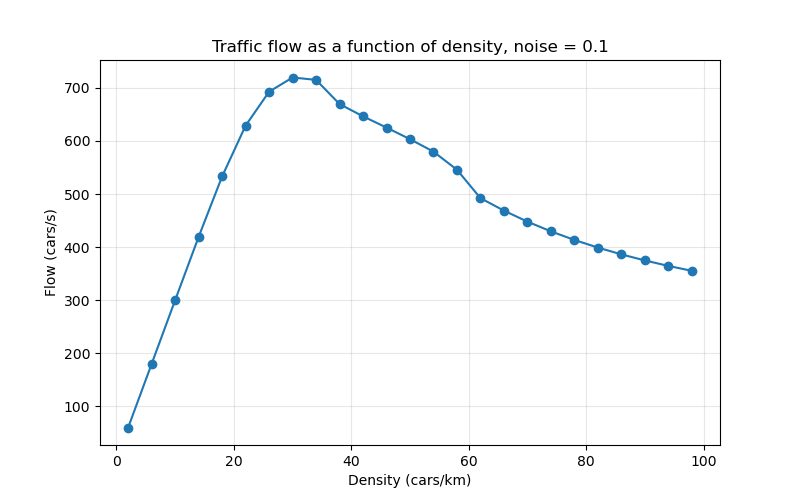

In [56]:
travel_all = []
velocities_all = []

noise = 0.1  # m
density = np.arange(2, 100, 4)

for n_cars in tqdm(density):
    positions_hist, velocities_hist = run_all(n_cars)
    travel_all.append(positions_hist)
    velocities_all.append(velocities_hist)

n_burnin = 5000

average_velocity = np.array([
    np.mean(velocity_hist[n_burnin:, :])
    for velocity_hist in velocities_all
])

flow = average_velocity * density

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(density, flow, 'o-')
ax.set_xlabel("Density (cars/km)")
ax.set_ylabel("Flow (cars/s)")
ax.set_title("Traffic flow as a function of density, noise = 0.1")
ax.grid(True, alpha=0.3)
plt.show()

The cell below animates the movement of the cars.

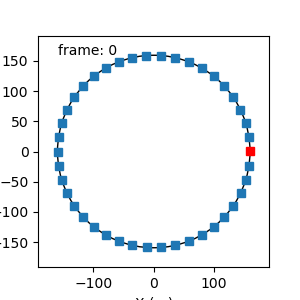

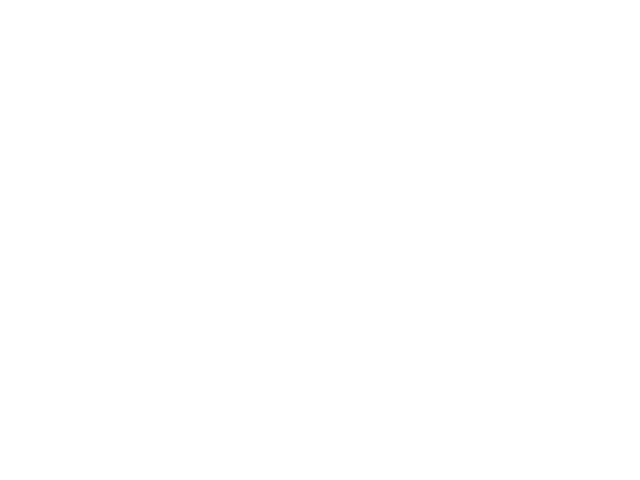

In [53]:
%matplotlib widget # when using widget, my other plots don't render
r = L / (2*np.pi)

plt.clf()
fig,ax = plt.subplots()

fig.set_size_inches(3,3)
fig.set_dpi(20)
ax.set_xlim([-1.2*r,1.2*r])
ax.set_ylim([-1.2*r,1.2*r])
ax.set_aspect(1)
c = plt.Circle([0,0],r,fill=False)
ax.add_patch(c)
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")

# Mid-density - try other number in range(len(density))
i_density=10
phi = travel_all[i_density][0]/L*2*np.pi

cars, = ax.plot(r*np.cos(phi[1:]),r*np.sin(phi[1:]),"s") 

# One of the cars is painted red to help observation
car0, = ax.plot(r*np.cos(phi[0:1]),r*np.sin(phi[0:1]),"rs") 
f = ax.text(-r,r,f"frame: {0}",)

def animate(i):

    phi = travel_all[i_density][i]/L*2*np.pi
    cars.set_xdata(r*np.cos(phi[1:]))
    cars.set_ydata(r*np.sin(phi[1:]))
    car0.set_xdata(r*np.cos(phi[0:1]))
    car0.set_ydata(r*np.sin(phi[0:1]))
    f.set_text(f"frame: {i}")
    
    return cars

# Adjust the range if needed.
ani = animation.FuncAnimation(
    fig, animate, frames=range(9000,10000),interval=50, blit=False)

plt.show()

The red car in the animation shows cyclic motion; when there is low density, the vehicle accelerates, eventually reaching constant speed when headway is at its largest. When it enters a high density region, it slows down and decelerates, repeating this cycle. This represents a moving traffic jam rather than a stationary point (such as a crashed car). 

#### Task

For each density, determine the average variation of velocities (after a suitable burn-in). Plot the average variation of velocity as a function of density. What kind of behaviour emerges?

[1 mark]

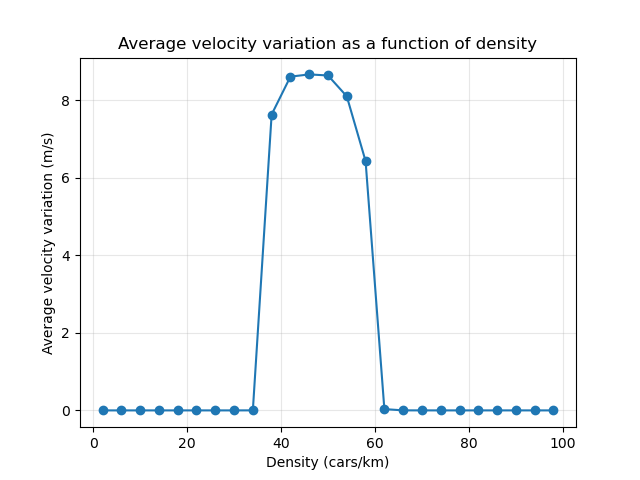

In [58]:
n_burnin = 5000

average_velocity_variation = np.array([
    np.mean(np.std(velocity_history[n_burnin:, :], axis=0))
    for velocity_history in velocities_all
])

fig, ax = plt.subplots()
ax.plot(density, average_velocity_variation, 'o-')
ax.set_xlabel("Density (cars/km)")
ax.set_ylabel("Average velocity variation (m/s)")
ax.set_title("Average velocity variation as a function of density")
ax.grid(True, alpha=0.3)
plt.show()

At low densities, the average velocity variation is 0, showing stable uniform flow. Between the densities of 35 and 65, the variation rises significantly, reaching a peak of around 8.5 m/s. This is the region where the start/stop motions in the animation develop. For higher velocities, the systems average velocity variation goes back down to zero, representing dense traffic. 

#### Extension

In the following, we have refined the model by adding a **thinking time** (drivers checking their phone when stationary and not paying attention) and **stopping threshold** (not bothering to get started if there is not enough distance in front of them). 

In [ ]:
def run_all_with_stopping(n_cars):
    
    # Initial conditions
    x = np.linspace(0,L,n_cars,endpoint=False)
    x += np.random.randn(n_cars)*noise
    v = np.zeros_like(x)

    # Integration timestep
    dt = 0.1 # s
    # number of integration steps
    n = 36000 

    s = distance(x,L)
    a = acceleration(s,v)

    travel = []
    velocities  = []

    # We use the velocity verlet algorithm
    prev_stopped_mask = np.array(np.zeros_like(x),dtype=bool)
    think_timer = np.zeros_like(x)
    think_timer[:] = thinking_time
    for i in range(n):
        #cars which are going less than stopping velocity and have low forward acceleration stop
        low_v_mask = v<stopping_threshold_v
        low_a_mask = (a>0) & (a<stopping_threshold_a)
        stop_mask = low_v_mask & low_a_mask
        v[stop_mask] = 0.0
        a[stop_mask] = 0.0
        
        # cars who now can go but were stopped are now thinking
        new_thinkers_mask = ((~stop_mask)&(prev_stopped_mask))
        think_timer[new_thinkers_mask] = 0.0
        thinking_mask = think_timer<thinking_time  
        
        # all thinkers are spending the timestep pondering
        v[thinking_mask] = 0.0
        a[thinking_mask] = 0.0
        think_timer[thinking_mask] += 1.0
        
        #update prev stopped mask
        prev_stopped_mask = stop_mask.copy()
        
        v += 0.5*a*dt
        x += v*dt
        s = distance(x,L)
        a = acceleration(s,v)
        v += 0.5*a*dt
        

        travel.append(x*1)
        velocities.append(v*1)

    travel = np.array(travel)
    velocities = np.array(velocities)
    return travel, velocities

stopping_threshold_v = 5 # if velocity less than this, stop cars
stopping_threshold_a = 10 # if magnitude of acceleration less than this, stop car
thinking_time = 20 #number of timesteps spent thinking after a stop

Run the simulation in the following for a range of densities, and use the cell below to animate the motion of cars.

In [ ]:
travel_all_with_stopping = []
velocities_all_with_stopping = []

density = np.arange(2,100,4)
noise = 0.2

for n_cars in tqdm(density):
    t_all, v_all = run_all_with_stopping(n_cars)
    travel_all_with_stopping.append(t_all)
    velocities_all_with_stopping.append(v_all)

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

Calculate the flow and plot it as a function of density. What do you observe? Comment on the results.

In [ ]:
n_burnin = ...


# YOUR CODE HERE
raise NotImplementedError()


average_velocity = np.array([np.mean(t_i[-1,:]-t_i[n_burnin,:])/(len(t_i)-n_burnin)/dt for t_i in travel_all_with_stopping])

fig,ax=plt.subplots()
ax.plot(density,average_velocity*density)
# Axis labels, prettification
# YOUR CODE HERE
raise NotImplementedError()
plt.show()

YOUR ANSWER HERE